> **這是已經執行過的版本**：每一格的結果（圖表、數字、聲音）都已經存在裡面，打開就能看，不需要登入或執行。
> 想自己動手執行，請改開 [互動版](https://colab.research.google.com/github/tehan0530/CYCU-fastenhancer-course/blob/main/notebook/FastEnhancer_handson.ipynb)（需要 Google 帳號）。
> 第 8 節「錄你自己的聲音」只能在互動版使用。

# FastEnhancer 手作課：讓聲音更清晰

這份 notebook 帶你一步一步完成**串流語音降噪**，從安裝到降噪都只要依序按下每個 cell 左邊的 ▶ 執行鍵，不需要改任何程式。

- 模型：[FastEnhancer](https://github.com/aask1357/fastenhancer)（Ahn et al., 2025），以 ONNX Runtime 執行
- 只需要 CPU：Colab 選單「執行階段 → 變更執行階段類型」選 **CPU** 就夠了
- 想在手機上即時試玩，請打開課堂網頁（網址見最後一節）

| 步驟 | 內容 |
|---|---|
| 0 | 安裝與下載 |
| 1 | 聽聽看、看頻譜圖 |
| 2 | 認識模型：輸入、輸出、記憶 |
| 3 | 串流降噪：一次 16 毫秒 |
| 4 | 速度：模型跑得比聲音快嗎？ |
| 5 | 延遲：聲音晚了多少？ |
| 6 | 實驗：拿掉記憶會怎樣？ |
| 7 | 實驗：噪音越大，模型還撐得住嗎？ |
| 8 | 錄你自己的聲音 |

## 0. 安裝與下載

安裝 `onnxruntime`（執行模型的引擎），並從 FastEnhancer 官方 GitHub 下載三個大小的模型：Tiny、Base、Small。
這三個模型都用 DNS-Challenge 的大量真實噪音訓練，取樣率 16 kHz。

In [1]:
!pip -q install onnxruntime soundfile

import os, time, urllib.request
import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
import onnxruntime as ort
from IPython.display import Audio, display

RELEASE = "https://github.com/aask1357/fastenhancer/releases/download/onnx-dns-v1.0.0"
# 課堂網頁（範例音檔放在這裡）
SITE = os.environ.get("FE_SITE", "https://benevolent-pithivier-3ffb14.netlify.app")

os.makedirs("models", exist_ok=True)
os.makedirs("samples", exist_ok=True)
for size in ["t", "b", "s"]:
    path = f"models/fastenhancer_{size}.onnx"
    if not os.path.exists(path):
        try:
            urllib.request.urlretrieve(f"{RELEASE}/fastenhancer_{size}.onnx", path)
        except Exception:   # 連不到 GitHub 時，改從課堂網頁下載同一個檔案
            urllib.request.urlretrieve(f"{SITE}/models/dns16k_{size}.onnx", path)
    print(path, f"{os.path.getsize(path) / 1024:.0f} KB")

for name in ["cafe", "metro", "station", "kitchen"]:
    for kind in ["noisy", "clean"]:
        path = f"samples/{name}_{kind}.wav"
        if not os.path.exists(path):
            urllib.request.urlretrieve(f"{SITE}/samples/{name}_{kind}.wav", path)
print("下載完成")

models/fastenhancer_t.onnx 122 KB


models/fastenhancer_b.onnx 404 KB


models/fastenhancer_s.onnx 813 KB


下載完成


## 1. 聽聽看、看頻譜圖

範例是英文語音混入真實環境噪音（咖啡廳、捷運車廂、車站、廚房）。
**SNR**（訊號雜訊比）表示人聲比噪音大多少，0 dB 代表兩者一樣大聲。

**頻譜圖**把聲音畫成一張圖：橫軸是時間，縱軸是頻率（下面低音、上面高音），越亮代表那個頻率越大聲。
人聲會呈現一條條橫向的「條紋」（諧波），噪音則像一片霧。

長度 5.9 秒，共 93691 個取樣點


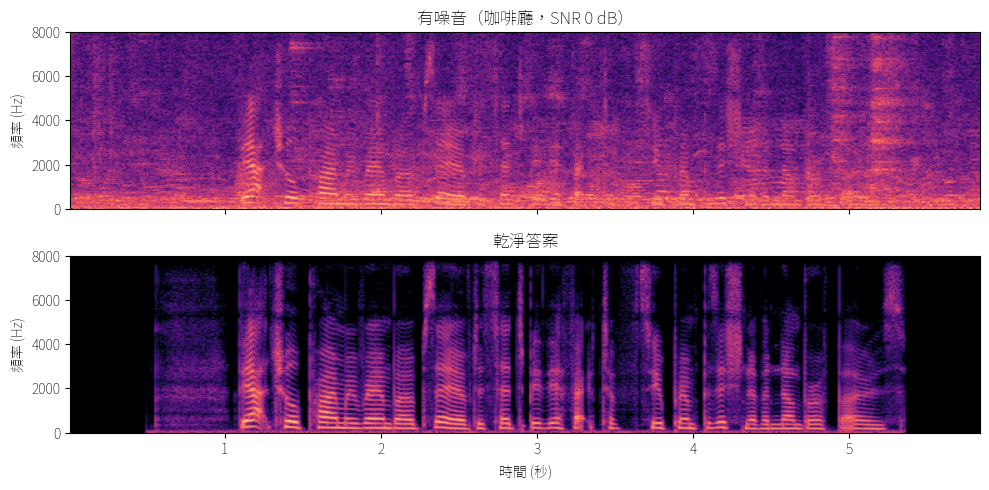

有噪音：


乾淨答案：


In [2]:
SR = 16000

def load(path):
    x, sr = sf.read(path, dtype="float32")
    assert sr == SR
    return x

def spec(ax, x, title):
    x = x + 1e-6 * np.random.randn(len(x))   # 避免完全無聲的地方算出 -∞
    ax.specgram(x, NFFT=512, Fs=SR, noverlap=384, cmap="magma", vmin=-110, vmax=-20)
    ax.set_title(title)
    ax.set_ylabel("頻率 (Hz)")

# 讓 matplotlib 能顯示中文：下載思源黑體（Noto Sans TC）
import warnings, matplotlib.font_manager as fm
warnings.filterwarnings("ignore")
FONT = "NotoSansTC.ttf"
if not os.path.exists(FONT):
    urllib.request.urlretrieve("https://github.com/google/fonts/raw/main/ofl/notosanstc/NotoSansTC%5Bwght%5D.ttf", FONT)
fm.fontManager.addfont(FONT)
plt.rcParams["font.family"] = [fm.FontProperties(fname=FONT).get_name(), "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

noisy = load("samples/cafe_noisy.wav")
clean = load("samples/cafe_clean.wav")
print(f"長度 {len(noisy) / SR:.1f} 秒，共 {len(noisy)} 個取樣點")

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
spec(axes[0], noisy, "有噪音（咖啡廳，SNR 0 dB）")
spec(axes[1], clean, "乾淨答案")
axes[1].set_xlabel("時間 (秒)")
plt.tight_layout(); plt.show()

print("有噪音："); display(Audio(noisy, rate=SR))
print("乾淨答案："); display(Audio(clean, rate=SR))

## 2. 認識模型：輸入、輸出、記憶

先看看模型要吃什麼、吐什麼：

- `wav_in`：**一小段**聲音，256 個取樣點。16 kHz 下等於 256 / 16000 = **16 毫秒**
- `cache_in_*`：模型的**記憶**。它只看得到這 16 毫秒，需要記住前面聽過什麼，才知道哪些是持續的噪音
- 輸出 `wav_out` 是降噪後的 16 毫秒，`cache_out_*` 是更新後的記憶，下一輪要再餵回去

In [3]:
def open_model(size="b"):
    opts = ort.SessionOptions()
    opts.intra_op_num_threads = 1   # 只用一個 CPU 核心，模擬手機或筆電
    return ort.InferenceSession(f"models/fastenhancer_{size}.onnx", opts, providers=["CPUExecutionProvider"])

model = open_model("b")
print("輸入：")
for i in model.get_inputs():
    print(f"  {i.name:12s} 形狀 {i.shape}")
print("輸出：")
for o in model.get_outputs():
    print(f"  {o.name:12s} 形狀 {o.shape}")

HOP = model.get_inputs()[0].shape[1]
print(f"\n一次處理 {HOP} 個取樣點 = {HOP / SR * 1000:.0f} 毫秒")

輸入：
  wav_in       形狀 [1, 256]
  cache_in_0   形狀 [1, 256]
  cache_in_1   形狀 [1, 256]
  cache_in_2   形狀 [1, 24, 36]
  cache_in_3   形狀 [1, 24, 36]
  cache_in_4   形狀 [1, 24, 36]
輸出：
  wav_out      形狀 [1, 256]
  cache_out_0  形狀 [1, 256]
  cache_out_1  形狀 [1, 256]
  cache_out_2  形狀 [1, 24, 36]
  cache_out_3  形狀 [1, 24, 36]
  cache_out_4  形狀 [1, 24, 36]

一次處理 256 個取樣點 = 16 毫秒


## 3. 串流降噪：一次 16 毫秒

這是整堂課的核心。真正的即時系統（視訊會議、助聽器）拿不到整段錄音，只能**一邊收音、一邊處理**。
所以我們把聲音切成一格一格的 16 毫秒，依序餵給模型，並且每次都把記憶傳下去。

```
聲音： [16ms][16ms][16ms][16ms] ...
          ↓     ↓     ↓     ↓
模型：  處理 → 處理 → 處理 → 處理 ...   （→ 是記憶 cache 往下傳）
          ↓     ↓     ↓     ↓
輸出： [16ms][16ms][16ms][16ms] ...
```

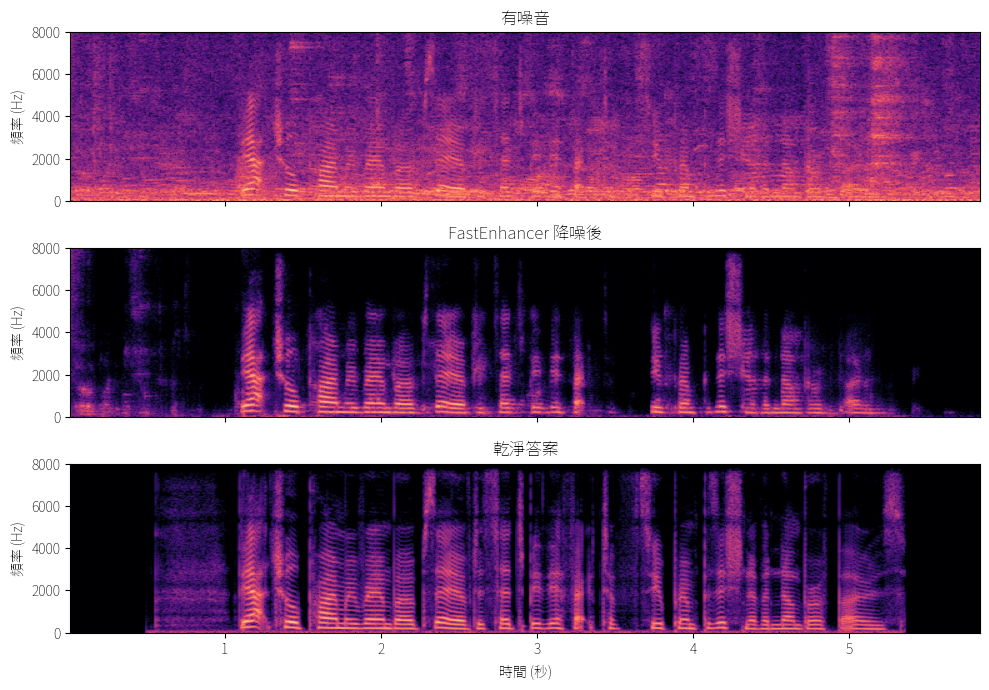

降噪後：


In [4]:
def enhance_streaming(model, x, keep_memory=True):
    hop = model.get_inputs()[0].shape[1]
    n = len(x)
    # 記憶一開始是全部 0
    memory = {i.name: np.zeros(i.shape, np.float32) for i in model.get_inputs() if i.name.startswith("cache_in")}
    # 補 0 湊成整數格，最後再多 1 格，把延遲的尾巴推出來
    x = np.concatenate([x, np.zeros((-n) % hop + hop, np.float32)])
    out = []
    for start in range(0, len(x), hop):
        chunk = x[start:start + hop][None, :]              # 取出 16 毫秒
        results = model.run(None, {"wav_in": chunk, **memory})
        out.append(results[0][0])                           # 降噪後的 16 毫秒
        if keep_memory:                                     # 把新的記憶傳給下一格
            for j, name in enumerate(memory):
                memory[name] = results[j + 1]
    y = np.concatenate(out)
    return y[hop:hop + n]                                   # 去掉 1 格延遲，對齊原始聲音

enhanced = enhance_streaming(model, noisy)

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
spec(axes[0], noisy, "有噪音")
spec(axes[1], enhanced, "FastEnhancer 降噪後")
spec(axes[2], clean, "乾淨答案")
axes[2].set_xlabel("時間 (秒)")
plt.tight_layout(); plt.show()

print("降噪後："); display(Audio(enhanced, rate=SR))

**換別的範例試試**：把下面的 `"metro"` 換成 `"station"` 或 `"kitchen"` 再執行。
注意廚房的鍋碗碰撞聲：這種突然出現的噪音，比咖啡廳那種持續的嗡嗡聲難處理。

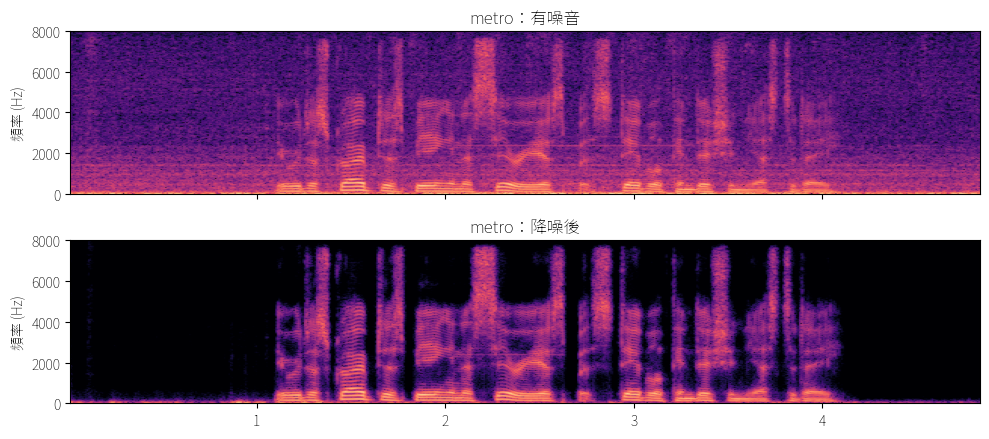

In [5]:
name = "metro"   # 可換成 "cafe"、"station"、"kitchen"

x = load(f"samples/{name}_noisy.wav")
y = enhance_streaming(model, x)
fig, axes = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
spec(axes[0], x, f"{name}：有噪音")
spec(axes[1], y, f"{name}：降噪後")
plt.tight_layout(); plt.show()
display(Audio(x, rate=SR)); display(Audio(y, rate=SR))

## 4. 速度：模型跑得比聲音快嗎？

即時處理的條件是：處理 16 毫秒的聲音，必須花**少於 16 毫秒**。

**RTF**（Real-Time Factor，即時因子）= 運算時間 ÷ 聲音長度。
- RTF < 1：跟得上即時
- RTF = 0.1：處理 1 秒的聲音只要 0.1 秒

下面比較 Tiny、Base、Small 三個模型。都只用**一個 CPU 核心**，跟手機或筆電差不多。

Tiny   處理 5.9 秒的聲音花了    206 ms   RTF = 0.035   每 16 ms 運算 0.56 ms


Base   處理 5.9 秒的聲音花了    314 ms   RTF = 0.054   每 16 ms 運算 0.86 ms


Small  處理 5.9 秒的聲音花了    451 ms   RTF = 0.077   每 16 ms 運算 1.23 ms


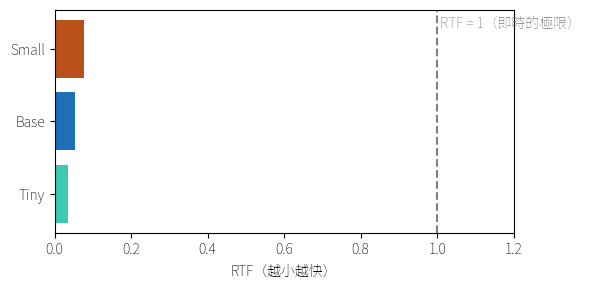

In [6]:
x = load("samples/cafe_noisy.wav")
sizes = {"t": "Tiny", "b": "Base", "s": "Small"}
rtfs = {}
for size, label in sizes.items():
    m = open_model(size)
    enhance_streaming(m, x[:SR])            # 先暖身一次
    t0 = time.perf_counter()
    enhance_streaming(m, x)
    sec = time.perf_counter() - t0
    rtfs[label] = sec / (len(x) / SR)
    print(f"{label:6s} 處理 {len(x) / SR:.1f} 秒的聲音花了 {sec * 1000:6.0f} ms   RTF = {rtfs[label]:.3f}   每 16 ms 運算 {rtfs[label] * 16:.2f} ms")

plt.figure(figsize=(6, 3))
plt.barh(list(rtfs), list(rtfs.values()), color=["#3cc9b3", "#1d6fb8", "#b8521a"])
plt.axvline(1.0, color="gray", ls="--"); plt.text(1.0, 2.3, " RTF = 1（即時的極限）", color="gray")
plt.xlabel("RTF（越小越快）"); plt.xlim(0, max(1.2, max(rtfs.values()) * 1.1))
plt.tight_layout(); plt.show()

## 5. 延遲：聲音晚了多少？

降噪後的聲音一定比原本的晚一點點。FastEnhancer 的輸出比輸入**晚 1 格（16 毫秒）**，
再加上收集這 1 格聲音也要 16 毫秒，所以模型本身的延遲大約是 **32 毫秒**。

人講話時，對話延遲大約在 150 毫秒以內就不太會察覺，所以 32 毫秒很夠用。
下面把**沒有對齊**的原始輸出放大來看，可以看到它整個往右移了一格。

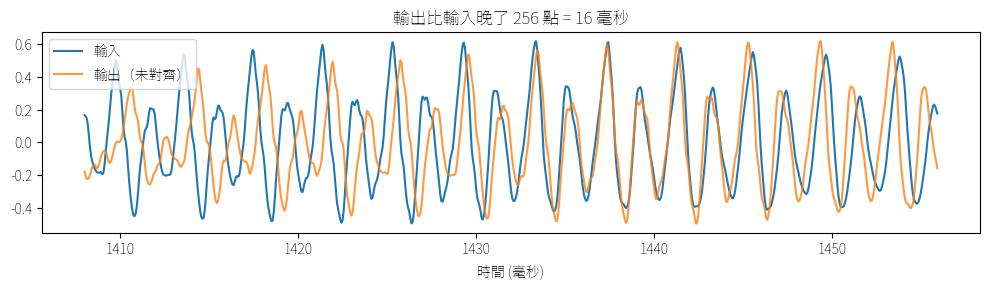

量到的延遲：256 個取樣點 = 16 毫秒


In [7]:
m = open_model("b")
memory = {i.name: np.zeros(i.shape, np.float32) for i in m.get_inputs() if i.name.startswith("cache_in")}
raw_out = []
xc = load("samples/cafe_clean.wav")
for start in range(0, len(xc) - HOP, HOP):
    r = m.run(None, {"wav_in": xc[None, start:start + HOP], **memory})
    raw_out.append(r[0][0])
    for j, name in enumerate(memory):
        memory[name] = r[j + 1]
raw_out = np.concatenate(raw_out)

# 自動挑一段最大聲的母音來畫
energy = [np.sum(xc[i:i + 3 * HOP] ** 2) for i in range(0, len(xc) - 4 * HOP, HOP)]
s0 = int(np.argmax(energy)) * HOP
seg = slice(s0, s0 + 3 * HOP)
t = np.arange(seg.start, seg.stop) / SR * 1000
plt.figure(figsize=(10, 3))
plt.plot(t, xc[seg], label="輸入")
plt.plot(t, raw_out[seg], label="輸出（未對齊）", alpha=0.8)
plt.xlabel("時間 (毫秒)"); plt.legend(); plt.title("輸出比輸入晚了 256 點 = 16 毫秒")
plt.tight_layout(); plt.show()

lag = np.argmax(np.correlate(raw_out[:SR * 3], xc[:SR * 3 - 1024], "valid")[:1024])
print(f"量到的延遲：{lag} 個取樣點 = {lag / SR * 1000:.0f} 毫秒")

## 6. 實驗：拿掉記憶會怎樣？

如果每一格都讓模型「失憶」（`keep_memory=False`，記憶永遠是 0），會發生什麼事？
先猜猜看，再執行。

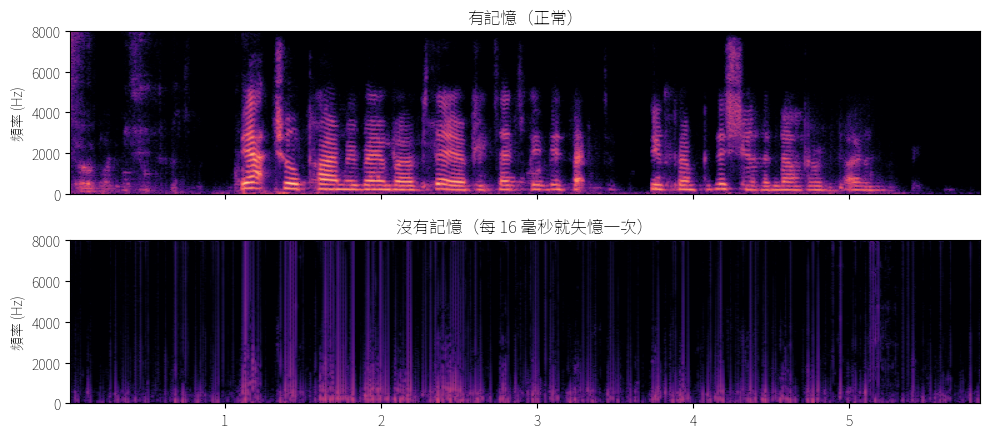

有記憶：


沒有記憶：


In [8]:
x = load("samples/cafe_noisy.wav")
with_mem = enhance_streaming(model, x, keep_memory=True)
no_mem = enhance_streaming(model, x, keep_memory=False)

fig, axes = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
spec(axes[0], with_mem, "有記憶（正常）")
spec(axes[1], no_mem, "沒有記憶（每 16 毫秒就失憶一次）")
plt.tight_layout(); plt.show()
print("有記憶："); display(Audio(with_mem, rate=SR))
print("沒有記憶："); display(Audio(no_mem, rate=SR))

**為什麼？** 只看 16 毫秒，模型分不出這是人聲還是噪音，也拼不回完整的波形。
記憶讓模型知道「剛剛一直都有這個嗡嗡聲，那它應該是噪音」。
串流模型的關鍵設計，就是**用很少的記憶記住過去**，而不是每次都重看整段聲音。

## 7. 實驗：噪音越大，模型還撐得住嗎？

我們手上有乾淨答案，所以可以自己調整噪音大小，並用 **SI-SDR** 打分數：
它衡量輸出和乾淨答案有多接近，單位是 dB，越高越好。

SNR  -5 dB：降噪前  -5.9 dB → 降噪後   2.7 dB


SNR  +0 dB：降噪前  -0.9 dB → 降噪後   8.8 dB


SNR  +5 dB：降噪前   4.2 dB → 降噪後  13.1 dB


SNR +10 dB：降噪前   9.2 dB → 降噪後  16.2 dB


SNR +20 dB：降噪前  19.2 dB → 降噪後  22.1 dB


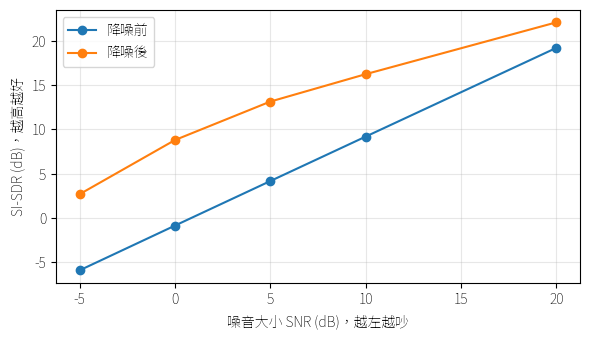

SNR −5 dB（噪音比人聲大聲）降噪前、後：


In [9]:
def si_sdr(est, ref):
    est, ref = est - est.mean(), ref - ref.mean()
    proj = (est @ ref) / (ref @ ref) * ref
    return 10 * np.log10((proj @ proj) / ((est - proj) @ (est - proj)))

clean = load("samples/cafe_clean.wav")
noise = load("samples/cafe_noisy.wav") - clean          # 噪音 = 有噪音 - 乾淨（範例原本是 0 dB）
snrs = [-5, 0, 5, 10, 20]
before, after = [], []
for snr in snrs:
    mix = clean + noise * 10 ** (-snr / 20)
    mix = mix / np.abs(mix).max() * 0.9
    out = enhance_streaming(model, mix.astype(np.float32))
    before.append(si_sdr(mix, clean)); after.append(si_sdr(out, clean))
    print(f"SNR {snr:+3d} dB：降噪前 {before[-1]:5.1f} dB → 降噪後 {after[-1]:5.1f} dB")

plt.figure(figsize=(6, 3.5))
plt.plot(snrs, before, "o-", label="降噪前")
plt.plot(snrs, after, "o-", label="降噪後")
plt.xlabel("噪音大小 SNR (dB)，越左越吵"); plt.ylabel("SI-SDR (dB)，越高越好")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

loudest = clean + noise * 10 ** (5 / 20)
loudest = (loudest / np.abs(loudest).max() * 0.9).astype(np.float32)
print("SNR −5 dB（噪音比人聲大聲）降噪前、後：")
display(Audio(loudest, rate=SR)); display(Audio(enhance_streaming(model, loudest), rate=SR))

## 8. 錄你自己的聲音

執行下面的 cell，瀏覽器會詢問麥克風權限，接著錄 5 秒。
可以邊講話邊敲桌子、搓塑膠袋、開風扇，看看哪些噪音消得掉。

In [10]:
from IPython.display import Javascript
from base64 import b64decode
import io, subprocess

try:
    from google.colab import output
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

RECORD_JS = '''
async function record(sec) {
  const stream = await navigator.mediaDevices.getUserMedia({audio: {noiseSuppression: false, echoCancellation: false, autoGainControl: false}});
  const rec = new MediaRecorder(stream); const chunks = [];
  rec.ondataavailable = e => chunks.push(e.data);
  rec.start(); await new Promise(r => setTimeout(r, sec * 1000)); rec.stop();
  await new Promise(r => rec.onstop = r); stream.getTracks().forEach(t => t.stop());
  const buf = await new Blob(chunks).arrayBuffer();
  let s = ''; new Uint8Array(buf).forEach(b => s += String.fromCharCode(b));
  return btoa(s);
}
'''

def record(sec=5):
    display(Javascript(RECORD_JS))
    print(f"錄音中，請講話 {sec} 秒…")
    data = b64decode(output.eval_js(f"record({sec})"))
    open("my_voice.webm", "wb").write(data)
    subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", "my_voice.webm", "-ac", "1", "-ar", str(SR), "my_voice.wav"], check=True)
    return load("my_voice.wav")

if IN_COLAB:
    mine = record(5)
    mine_enh = enhance_streaming(model, mine)
    fig, axes = plt.subplots(2, 1, figsize=(10, 4.5), sharex=True)
    spec(axes[0], mine, "我的錄音"); spec(axes[1], mine_enh, "降噪後")
    plt.tight_layout(); plt.show()
    print("原始："); display(Audio(mine, rate=SR))
    print("降噪後："); display(Audio(mine_enh, rate=SR))
else:
    print("這個 cell 需要在 Colab 執行")

這個 cell 需要在 Colab 執行


## 延伸

- **課堂網頁**：https://benevolent-pithivier-3ffb14.netlify.app（在手機上即時降噪，模型直接在手機裡跑）
- **FastEnhancer 原始碼與論文**：<https://github.com/aask1357/fastenhancer>，[arXiv:2509.21867](https://arxiv.org/abs/2509.21867)
- **自己架一份課堂網頁**：[課程 GitHub repo](https://github.com/tehan0530/CYCU-fastenhancer-course) 的 README「自己架一份」有 Netlify、本機、GitHub Pages 三種方式
- **想自己訓練模型？** 官方文件有完整的資料準備與訓練流程：<https://aask1357.github.io/fastenhancer/>

範例音檔：VCTK / VoiceBank 語音（CC BY 4.0）混合 DEMAND 環境噪音（CC BY-SA 3.0）。